# 07 · Spatial models (stochastic PDEs)

Fields can live in one to three spatial dimensions. A spatial model adds `spatial_dim(d)` and a Laplacian in the linear operator, for example the stochastic Allen–Cahn equation

$$\partial_t\phi = \Delta\phi - m\,\phi - g\,\phi^3 + \eta, \qquad \langle\eta(x,t)\eta(x',t')\rangle = 2D\,\delta(x-x')\,\delta(t-t').$$

Loop integrals over momenta are done by Symanzik / causal-chamber parametrisations with analytic heat-kernel transforms; equal-time correlations are returned as functions of the separation $\chi = x - x'$. Spatial models are written as model files (or with the builder) rather than with the SDE front end.

The spatial examples are the place to start:

| Notebook | Shows |
|---|---|
| [`SPDE/Allen_Cahn_phi4`](../examples/SPDE/Allen_Cahn_phi4.ipynb) | a $\phi^4$ field in $d = 1$; the one-loop self-energy |
| [`SPDE/RD_2D`](../examples/SPDE/RD_2D.ipynb) | $d = 2$ with a UV-finite loop |
| [`SPDE/RD_2_species`](../examples/SPDE/RD_2_species.ipynb) | two coupled species, cross-correlations, Dyson dressing for unequal diffusion |

Design notes: [`docs/spatial_pipeline.md`](../../docs/spatial_pipeline.md). A short run (about a minute):

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

────────────────────────────────────────────────────────────────────────
  1D stochastic Allen-Cahn (subcritical, infinite domain)
────────────────────────────────────────────────────────────────────────
Domain         : SPDE · d=1 · boundary=infinite · initial=stationary
Fields         : phi (x∈ℝ^1) — order parameter
Response fields: phit
Mean-field saddle: phistar
Governing eqn  : (Dt + mu - D*Laplacian)*phi = -lam*phi^3
Action  S      : phit*((Dt + mu - D*Laplacian)*phi + lam*phi^3) - T*phit^2
Parameters (defaults):
    mu = 1.0  (positive)
    D = 1.0  (positive)
    lam = 0.1  (positive)
    T = 1.0  (positive)
Suggested run  : k=2, max_ell=0

1D stochastic Allen-Cahn (subcritical, infinite domain) — spatial v1
test model.

The first spatial field theory in Daedalus.  Off-critical (μ > 0),
infinite domain, stationary initial condition.  Free part is an
Ornstein-Uhlenbeck-in-time × heat-kernel-in-space propagator; the
λφ³ vertex drives the 1-loop self-energy correction.

    (∂_t +

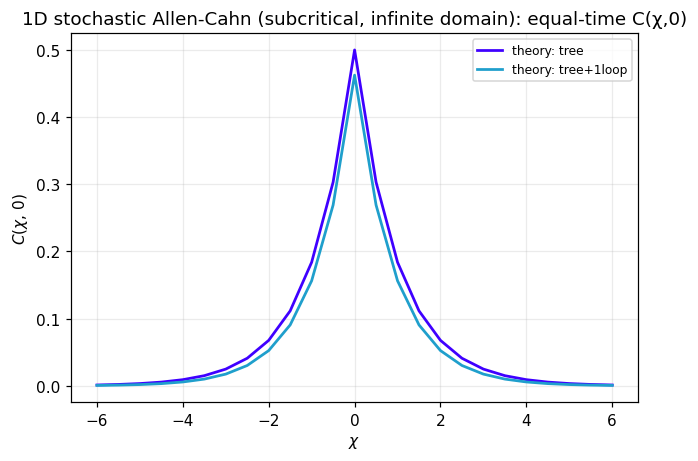

In [2]:
import daedalus as dd
model, mod = dd.load_model('allen_cahn_1d_subcritical_infinite')
dd.describe_model(model, mod)
cfg = dd.Config(k=2, max_ell=1, chi_grid=(-6, 6, 25), parallel=False)
t0 = time.time()
res = dd.run(model, cfg, mod)
print(f"{time.time() - t0:.0f} s")
dd.plot_cumulant(res, cfg, model); plt.show()